# Model Evaluation

Visualises the artefacts produced by `make train` (or `uv run python -m src.models.train`).

**Expected artefacts** (relative to repo root):
- `models/training_metrics.json`
- `models/feature_importance.json`
- `models/feature_cols.json`
- `models/lgbm_forecaster.txt`
- `data/sample/train_sample.parquet`  *(benchmark data written by train pipeline)*

In [1]:
import plotly.io as pio
pio.renderers.default = 'png'
from __future__ import annotations

import json
import sys
from pathlib import Path

import lightgbm as lgb
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
import polars as pl
from plotly.subplots import make_subplots

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))  # allow importing src.*

MODELS_DIR = REPO_ROOT / "models"
DATA_DIR = REPO_ROOT / "data" / "sample"

## 1. Cross-Validation NWRMSLE by Fold

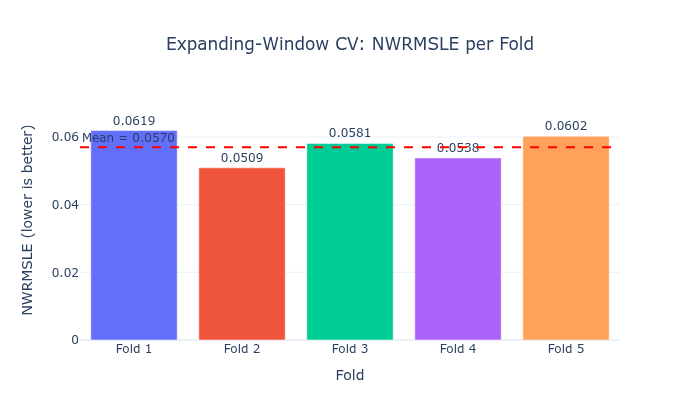

In [2]:
with (MODELS_DIR / "training_metrics.json").open() as f:
    metrics = json.load(f)

fold_scores: list[float] = metrics["fold_nwrmsle"]
mean_score: float = metrics["mean_nwrmsle"]
fold_labels = [f"Fold {i + 1}" for i in range(len(fold_scores))]

fig_cv = go.Figure()
fig_cv.add_trace(
    go.Bar(
        x=fold_labels,
        y=fold_scores,
        marker_color=px.colors.qualitative.Plotly[:len(fold_scores)],
        text=[f"{s:.4f}" for s in fold_scores],
        textposition="outside",
        name="Fold NWRMSLE",
    )
)
fig_cv.add_hline(
    y=mean_score,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Mean = {mean_score:.4f}",
    annotation_position="top left",
)
fig_cv.update_layout(
    title=dict(text="Expanding-Window CV: NWRMSLE per Fold", x=0.5),
    xaxis_title="Fold",
    yaxis_title="NWRMSLE (lower is better)",
    template="plotly_white",
    showlegend=False,
    height=420,
)
fig_cv.show()

## 2. Feature Importance — Top 20

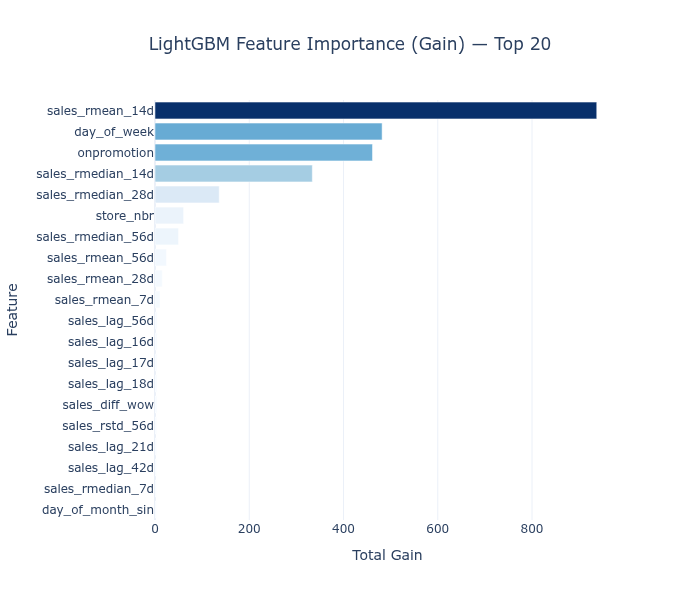

In [3]:
with (MODELS_DIR / "feature_importance.json").open() as f:
    fi_raw: dict[str, float] = json.load(f)

fi_df = (
    pl.DataFrame({"feature": list(fi_raw.keys()), "gain": list(fi_raw.values())})
    .sort("gain", descending=True)
    .head(20)
)

fig_fi = px.bar(
    fi_df.to_pandas(),
    x="gain",
    y="feature",
    orientation="h",
    title="LightGBM Feature Importance (Gain) — Top 20",
    labels={"gain": "Total Gain", "feature": "Feature"},
    color="gain",
    color_continuous_scale="Blues",
    template="plotly_white",
    height=600,
)
fig_fi.update_layout(
    title_x=0.5,
    yaxis={"categoryorder": "total ascending"},
    coloraxis_showscale=False,
)
fig_fi.show()

## 3. Prepare Evaluation Data

Apply the same feature pipeline used during training so the matrix matches the saved model.

In [4]:
from src.features.aggregations import build_lag_features
from src.features.temporal import build_temporal_features

# Load feature column list saved by training pipeline
with (MODELS_DIR / "feature_cols.json").open() as f:
    feature_cols: list[str] = json.load(f)

TARGET_COL = "unit_sales"

# Load raw benchmark data and apply the same feature engineering
df_raw = pl.read_parquet(DATA_DIR / "train_sample.parquet")
df_feat = build_temporal_features(df_raw.lazy()).collect()
df_feat = build_lag_features(df_feat.lazy(), target_col=TARGET_COL).collect()
df_feat = df_feat.drop_nulls(subset=feature_cols)

print(f"Engineered dataset: {df_feat.shape}  |  Features: {len(feature_cols)}")

# Load the trained model
booster = lgb.Booster(model_file=str(MODELS_DIR / "lgbm_forecaster.txt"))

X = df_feat.select(feature_cols).to_numpy()
preds_log = booster.predict(X)

df_eval = df_feat.with_columns(
    (pl.Series(name="pred_log", values=preds_log).exp() - 1.0).clip(0.0).alias("prediction")
)

print("Predictions generated successfully.")

Engineered dataset: (1968, 52)  |  Features: 48
Predictions generated successfully.


## 4. Prediction vs Actual — Sample Store + Family

Store 1 | Family 'GROCERY I' | Rows: 164


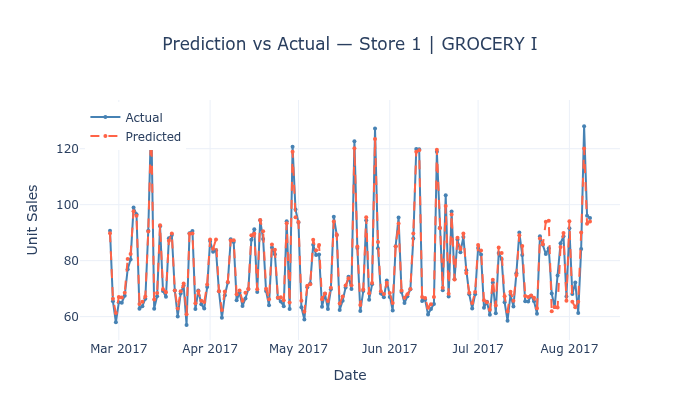

In [5]:
# Pick first available store + family
first_store = int(df_eval["store_nbr"][0])
first_family = str(df_eval["family"][0])

sample = (
    df_eval
    .filter(
        (pl.col("store_nbr") == first_store) & (pl.col("family") == first_family)
    )
    .sort("date")
    .select(["date", TARGET_COL, "prediction"])
    .to_pandas()
)

print(f"Store {first_store} | Family '{first_family}' | Rows: {len(sample)}")

fig_ts = go.Figure()
fig_ts.add_trace(
    go.Scatter(
        x=sample["date"], y=sample[TARGET_COL],
        mode="lines+markers", name="Actual",
        line=dict(color="steelblue", width=2), marker=dict(size=4),
    )
)
fig_ts.add_trace(
    go.Scatter(
        x=sample["date"], y=sample["prediction"],
        mode="lines+markers", name="Predicted",
        line=dict(color="tomato", width=2, dash="dash"), marker=dict(size=4),
    )
)
fig_ts.update_layout(
    title=dict(text=f"Prediction vs Actual — Store {first_store} | {first_family}", x=0.5),
    xaxis_title="Date", yaxis_title="Unit Sales",
    template="plotly_white", legend=dict(x=0.01, y=0.99), height=420,
)
fig_ts.show()

## 5. Residual Distribution

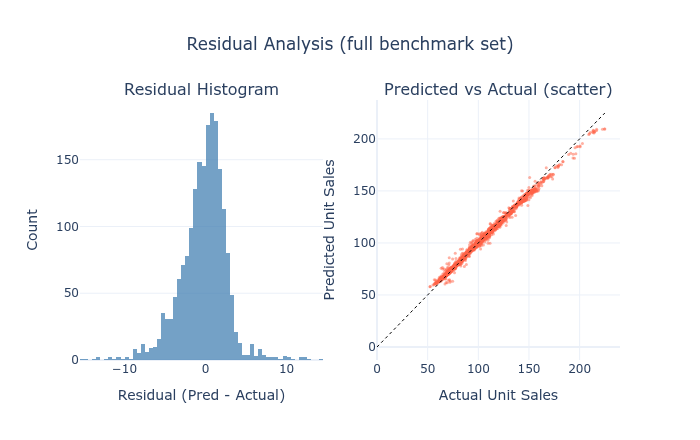

In [6]:
all_preds = df_eval["prediction"].to_numpy()
all_actuals = df_eval[TARGET_COL].to_numpy()
residuals = all_preds - all_actuals

fig_res = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Residual Histogram", "Predicted vs Actual (scatter)"),
)
fig_res.add_trace(
    go.Histogram(x=residuals, nbinsx=60, marker_color="steelblue", opacity=0.75, name="Residuals"),
    row=1, col=1,
)
fig_res.add_trace(
    go.Scatter(
        x=all_actuals, y=all_preds, mode="markers",
        marker=dict(color="tomato", size=3, opacity=0.5), name="Pred vs Actual",
    ),
    row=1, col=2,
)
max_val = float(max(all_actuals.max(), all_preds.max()))
fig_res.add_trace(
    go.Scatter(
        x=[0, max_val], y=[0, max_val], mode="lines",
        line=dict(color="black", dash="dot", width=1), name="Perfect fit",
    ),
    row=1, col=2,
)
fig_res.update_layout(
    title=dict(text="Residual Analysis (full benchmark set)", x=0.5),
    template="plotly_white", height=440, showlegend=False,
)
fig_res.update_xaxes(title_text="Residual (Pred - Actual)", row=1, col=1)
fig_res.update_yaxes(title_text="Count", row=1, col=1)
fig_res.update_xaxes(title_text="Actual Unit Sales", row=1, col=2)
fig_res.update_yaxes(title_text="Predicted Unit Sales", row=1, col=2)
fig_res.show()

## 6. Summary Table

In [7]:
from IPython.display import display
from src.models.metrics import nwrmsle_numpy

# Compute full-dataset NWRMSLE (in-sample, for reference only)
weight_col = df_eval["weight"].to_numpy() if "weight" in df_eval.columns else None
insample_score = nwrmsle_numpy(all_actuals, all_preds, weight_col)

summary = {
    "Model type": metrics.get("model_type", "LightGBM"),
    "CV folds": metrics["n_folds"],
    "Horizon (days)": metrics["horizon_days"],
    "Features": metrics["n_features"],
    "Mean CV NWRMSLE": f"{mean_score:.4f}",
    "Best fold": f"{min(fold_scores):.4f}",
    "Worst fold": f"{max(fold_scores):.4f}",
    "In-sample NWRMSLE": f"{insample_score:.4f}",
    "Residual mean": f"{float(residuals.mean()):.4f}",
    "Residual std": f"{float(residuals.std()):.4f}",
    "Benchmark rows": len(df_eval),
    "Trained at": metrics.get("timestamp", "N/A"),
}

display(
    pl.DataFrame({
        "Metric": list(summary.keys()),
        "Value": [str(v) for v in summary.values()],
    })
)

Metric,Value
str,str
"""Model type""","""LightGBM"""
"""CV folds""","""5"""
"""Horizon (days)""","""16"""
"""Features""","""48"""
"""Mean CV NWRMSLE""","""0.0570"""
…,…
"""In-sample NWRMSLE""","""0.0280"""
"""Residual mean""","""-0.2525"""
"""Residual std""","""2.9202"""
